<a href="https://colab.research.google.com/github/leonIceHot/Computer-Vision-Course/blob/main/CH0_OpenCV_Fundamentals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# OpenCV 基礎概念整合

## 學習目標
- 理解 OpenCV 函式庫的整體架構
- 掌握 OpenCV 核心模組功能
- 熟悉常用函數與最佳實踐
- 學會錯誤處理與除錯技巧

In [ ]:
import cv2
import numpy as np

print(f'✅ OpenCV version: {cv2.__version__}')
print(f'✅ NumPy version: {np.__version__}')


✅ OpenCV version: 5.0.0
✅ NumPy version: 2.4.6


## 1. OpenCV 架構概覽

### OpenCV 核心模組

```
OpenCV 5.x（主庫）
├── core        # 核心：Mat、MatShape、基本算術、平行化
├── imgproc      # 影像處理：濾波、幾何變換、形態學、直方圖、輪廓
├── imgcodecs     # 影像讀寫：imread / imwrite / imdecode
├── videoio      # 視訊 I/O：VideoCapture / VideoWriter
├── highgui      # 視窗與事件：imshow / waitKey / createTrackbar
├── video       # 視訊分析：光流、背景相減、追蹤
├── geometry      # 幾何基本元件：單應性、三角化、USAC 穩健估計
├── calib       # 相機校正與姿態：calibrateCamera、solvePnP
├── stereo      # 立體對應：StereoBM、StereoSGBM
├── ptcloud      # 點雲處理：PLY/OBJ 讀寫、基本幾何
├── features      # 特徵框架（原 features2d）：SIFT、ORB、ALIKED、LightGlue
├── flann       # 多維空間的聚類與最近鄰搜尋
├── objdetect     # 物體檢測：Haar、HOG、QRCode、FaceDetectorYN
├── photo       # 計算攝影：去噪、修補、HDR、無縫融合
├── stitching     # 全景拼接
└── dnn         # 深度學習推理：以 ONNX 為主（新引擎 CPU-only）
```

### opencv_contrib
```
opencv_contrib（需另外安裝）
├── ximgproc    # 保邊濾波、細化、結構化邊緣
├── xfeatures2d # 實驗性／專利類特徵（SURF 等）
├── ml          # 傳統機器學習（SVM、KNN）
├── gapi        # G-API（圖形化推論管線）
├── dnn_superres / dnn_objdetect
└── tracking / bgsegm / face …
```

### 模組依賴關係

```
      core (基礎)
         ↓
    imgproc (影像處理)
         ↓
  ┌────────────────┐
  ↓                ↓
video          features2d
  ↓                ↓
calib3d      objdetect
```

In [ ]:
# 檢查可用模組
import cv2

available_modules = [
    'core', 'imgproc', 'imgcodecs', 'videoio', 'highgui',
    'video', 'calib3d', 'features2d', 'objdetect', 'ml', 'dnn'
]

print('Available OpenCV Modules:')
print('=' * 50)
for module in available_modules:
    status = '✅' if hasattr(cv2, module) else '❌'
    print(f'{status} cv2.{module}')

print(f'\n🔧 Total submodules: {len([m for m in dir(cv2) if not m.startswith("_")])}')

Available OpenCV Modules:
❌ cv2.core
❌ cv2.imgproc
❌ cv2.imgcodecs
❌ cv2.videoio
❌ cv2.highgui
❌ cv2.video
❌ cv2.calib3d
❌ cv2.features2d
❌ cv2.objdetect
❌ cv2.ml
✅ cv2.dnn

🔧 Total submodules: 2504


## 2. 核心資料結構

### 2.1 Mat (Matrix) - OpenCV 核心資料類型

在 Python 中，OpenCV 使用 **NumPy ndarray** 代替 C++ 的 `Mat`。

```python
# NumPy ndarray = OpenCV Mat
img: np.ndarray  # shape: (height, width, channels)
```

### 關鍵屬性

| 屬性 | 說明 | 範例 |
|------|------|------|
| `shape` | (高度, 寬度, 通道數) | `(480, 640, 3)` |
| `dtype` | 資料型別 | `uint8`, `float32` |
| `size` | 總元素數 | `921600` |
| `ndim` | 維度數 | `3` (彩色), `2` (灰階) |

In [ ]:
# 創建不同類型的影像

# 1. 灰階影像 (單通道)
gray = np.zeros((200, 300), dtype=np.uint8)

# 2. 彩色影像 (三通道 BGR)
bgr = np.zeros((200, 300, 3), dtype=np.uint8)

# 3. 帶透明度影像 (四通道 BGRA)
bgra = np.zeros((200, 300, 4), dtype=np.uint8)

# 4. 浮點數影像
float_img = np.zeros((200, 300, 3), dtype=np.float32)

print('影像屬性對照表:')
print('=' * 60)
for name, img in [('Gray', gray), ('BGR', bgr), ('BGRA', bgra), ('Float', float_img)]:
    print(f'{name:8} | shape: {str(img.shape):15} | dtype: {img.dtype} | size: {img.size}')

影像屬性對照表:
Gray     | shape: (200, 300)      | dtype: uint8 | size: 60000
BGR      | shape: (200, 300, 3)   | dtype: uint8 | size: 180000
BGRA     | shape: (200, 300, 4)   | dtype: uint8 | size: 240000
Float    | shape: (200, 300, 3)   | dtype: float32 | size: 180000


### 2.2 常用資料結構

#### Point / Point2f / Point3f
```python
# 2D 點座標
pt = (100, 200)  # (x, y)
pt_f = (100.5, 200.3)  # 浮點數座標

# 3D 點座標
pt_3d = (100, 200, 50)  # (x, y, z)
```

#### Rect (矩形)
```python
# (x, y, width, height)
rect = (50, 50, 100, 100)
```

#### Scalar (純量/顏色)
```python
# BGR 顏色
blue = (255, 0, 0)
green = (0, 255, 0)
red = (0, 0, 255)
white = (255, 255, 255)
```

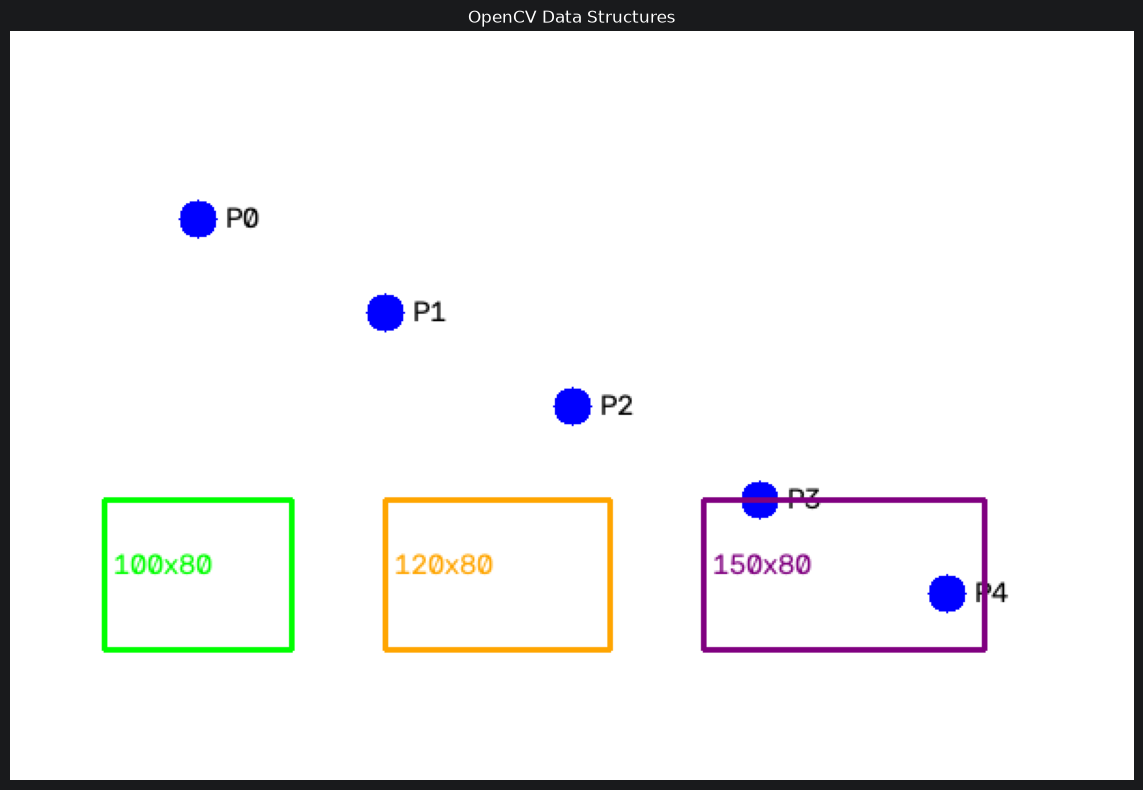

In [ ]:
import cv2
import matplotlib.pyplot as plt

def display_image(img, title='Image', figsize=(10, 6)):
    # BGR → RGB via numpy slice, no cv2 needed
    rgb = img[..., ::-1]
    plt.figure(figsize=figsize)
    plt.imshow(rgb)
    plt.title(title)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# 資料結構示範
canvas = np.ones((400, 600, 3), dtype=np.uint8) * 255

# Point: 繪製圓點
points = [(100, 100), (200, 150), (300, 200), (400, 250), (500, 300)]
for i, pt in enumerate(points):
    cv2.circle(canvas, pt, 10, (255, 0, 0), -1)
    cv2.putText(canvas, f'P{i}', (pt[0]+15, pt[1]+5),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1)

# Rect: 繪製矩形
rects = [(50, 250, 100, 80), (200, 250, 120, 80), (370, 250, 150, 80)]
colors = [(0, 255, 0), (0, 165, 255), (128, 0, 128)]  # Green, Orange, Purple

for rect, color in zip(rects, colors):
    x, y, w, h = rect
    cv2.rectangle(canvas, (x, y), (x+w, y+h), color, 2)
    cv2.putText(canvas, f'{w}x{h}', (x+5, y+h//2),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

display_image(canvas, title='OpenCV Data Structures', figsize=(12, 8))


## 3. 常用函數速查表

### 3.1 影像 I/O

| 函數 | 功能 | 範例 |
|------|------|------|
| `cv2.imread()` | 讀取影像 | `img = cv2.imread('image.jpg')` |
| `cv2.imwrite()` | 儲存影像 | `cv2.imwrite('output.jpg', img)` |
| `cv2.imshow()` | 顯示影像 | `cv2.imshow('window', img)` |
| `cv2.waitKey()` | 等待按鍵 | `cv2.waitKey(0)` |
| `cv2.destroyAllWindows()` | 關閉視窗 | `cv2.destroyAllWindows()` |

### 3.2 色彩空間轉換

| 轉換 | 函數 |
|------|------|
| BGR → RGB | `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` |
| BGR → Gray | `cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)` |
| BGR → HSV | `cv2.cvtColor(img, cv2.COLOR_BGR2HSV)` |
| Gray → BGR | `cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)` |

### 3.3 幾何變換

| 函數 | 功能 | 範例 |
|------|------|------|
| `cv2.resize()` | 縮放 | `cv2.resize(img, (w, h))` |
| `cv2.flip()` | 翻轉 | `cv2.flip(img, 1)  # 水平` |
| `cv2.rotate()` | 旋轉 | `cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)` |
| `cv2.warpAffine()` | 仿射變換 | `cv2.warpAffine(img, M, (w, h))` |
| `cv2.warpPerspective()` | 透視變換 | `cv2.warpPerspective(img, M, (w, h))` |

### 3.4 濾波與平滑

| 函數 | 功能 |
|------|------|
| `cv2.GaussianBlur()` | 高斯濾波 |
| `cv2.medianBlur()` | 中值濾波 |
| `cv2.bilateralFilter()` | 雙邊濾波 |
| `cv2.filter2D()` | 自定義卷積 |

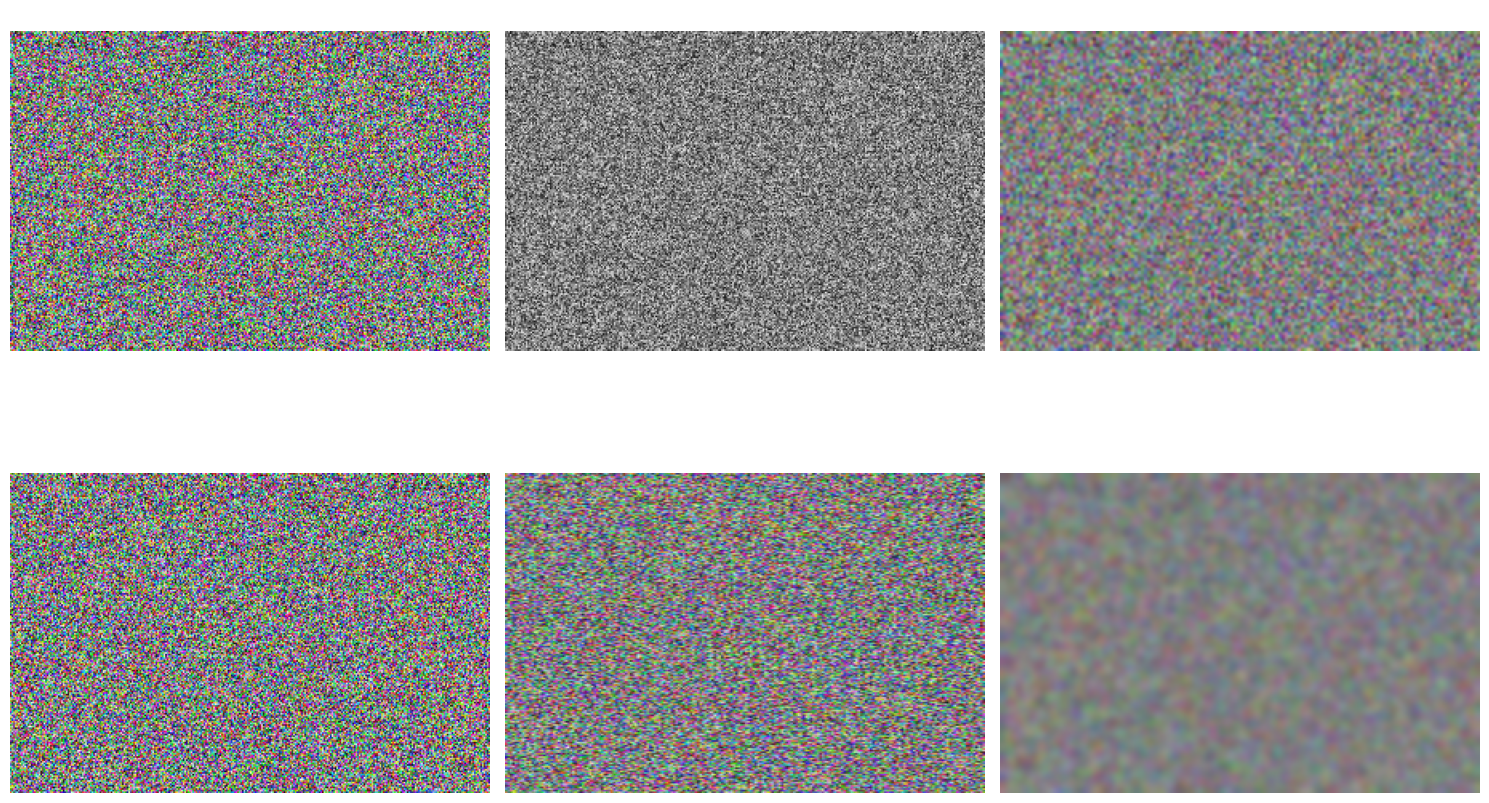

In [ ]:
import cv2
import matplotlib.pyplot as plt

def display_multiple_images(images, titles, rows=2, cols=3, figsize=(15, 10)):
    """
    Display multiple images in a grid layout.

    Parameters
    ----------
    images : list of np.ndarray
        Images in BGR channel order (as produced by OpenCV).
    titles : list of str
        Title for each image; must match len(images).
    rows : int
        Number of grid rows.
    cols : int
        Number of grid columns.
    figsize : tuple
        Overall figure size in inches (width, height).
    """
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    fig.patch.set_facecolor('white')

    ax_flat = axes.ravel() if rows * cols > 1 else [axes]

    for ax, img, title in zip(ax_flat, images, titles):
        ax.imshow(img[..., ::-1])   # BGR → RGB
        ax.set_title(title, fontsize=12)
        ax.axis('off')

    # hide any unused subplot slots
    for ax in ax_flat[len(images):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()

# 創建測試影像
test_img = np.random.randint(0, 256, (200, 300, 3), dtype=np.uint8)

# 常用操作示範
operations = []

# 1. 色彩空間轉換
gray = cv2.cvtColor(test_img, cv2.COLOR_BGR2GRAY)
gray_bgr = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
operations.append(('Grayscale', gray_bgr))

# 2. 縮放
resized = cv2.resize(test_img, (150, 100))
resized_back = cv2.resize(resized, (300, 200))
operations.append(('Resized', resized_back))

# 3. 翻轉
flipped = cv2.flip(test_img, 1)  # 水平翻轉
operations.append(('Flipped', flipped))

# 4. 旋轉
rotated = cv2.rotate(test_img, cv2.ROTATE_90_CLOCKWISE)
rotated_back = cv2.resize(rotated, (300, 200))
operations.append(('Rotated 90°', rotated_back))

# 5. 高斯模糊
blurred = cv2.GaussianBlur(test_img, (15, 15), 0)
operations.append(('Gaussian Blur', blurred))

# 顯示結果
images = [test_img] + [img for _, img in operations]
titles = ['Original'] + [title for title, _ in operations]

display_multiple_images(images, titles, rows=2, cols=3, figsize=(15, 10))

## 4. Hello OpenCV - 完整範例

### 基本工作流程

```python
# 1. 讀取影像
img = cv2.imread('input.jpg')

# 2. 處理影像
processed = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 3. 儲存結果
cv2.imwrite('output.jpg', processed)

# 4. 顯示影像
cv2.imshow('Result', processed)
cv2.waitKey(0)
cv2.destroyAllWindows()
```

🚀 Starting Hello OpenCV workflow...
✅ Step 1: Created image
✅ Step 2: Converted color spaces
✅ Step 3: Applied filters


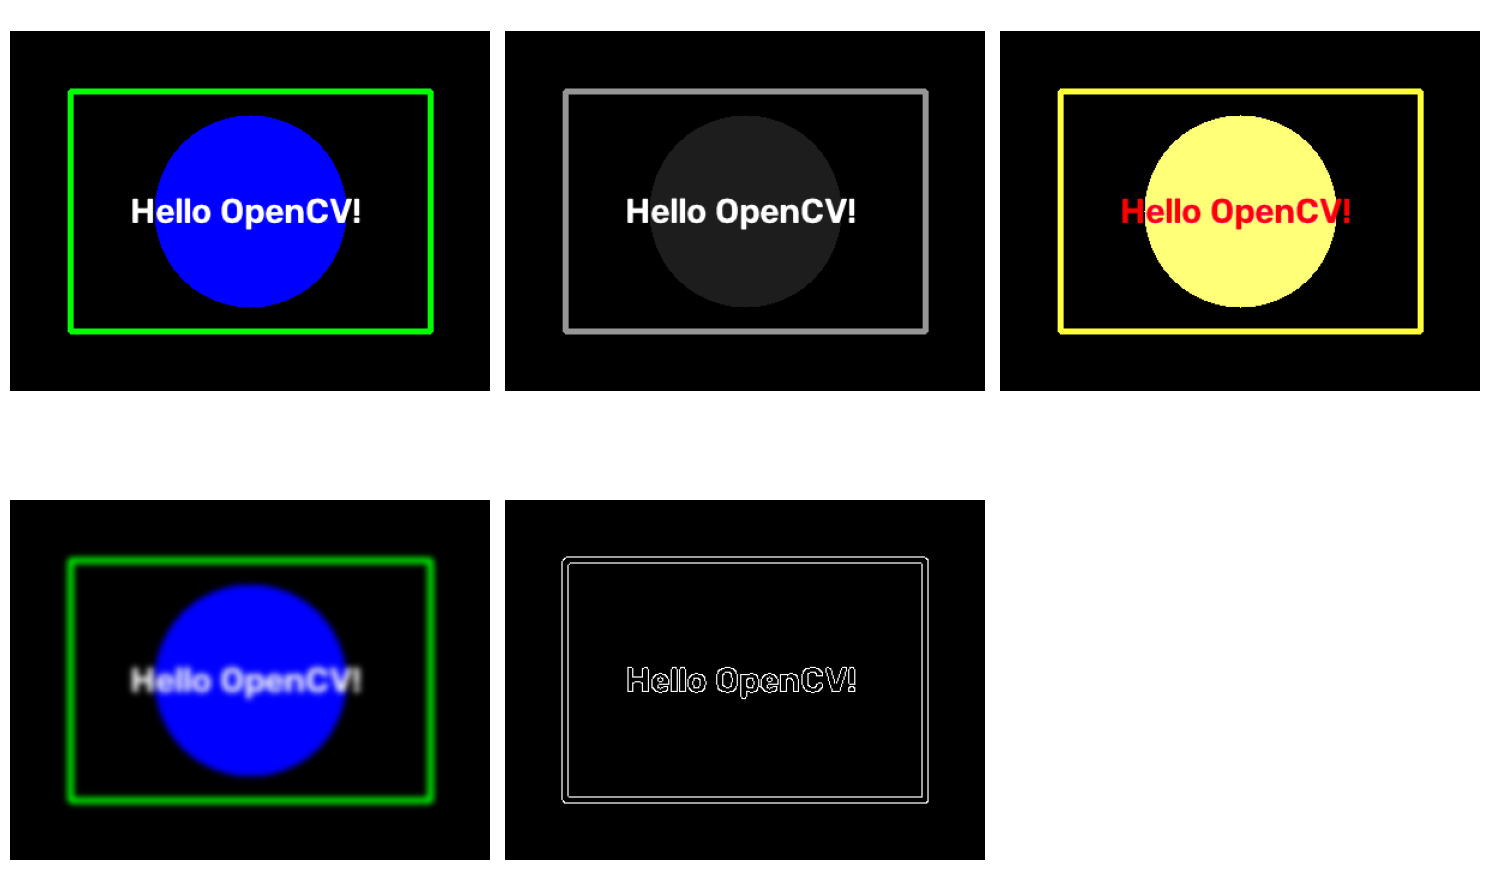

✅ Step 4: Displayed results
🎉 Hello OpenCV workflow completed!


In [ ]:
# Hello OpenCV - 完整工作流程

def hello_opencv():
    """
    OpenCV 基礎工作流程示範
    """
    print('🚀 Starting Hello OpenCV workflow...')

    # 1. 創建示範影像
    img = np.zeros((300, 400, 3), dtype=np.uint8)

    # 2. 繪製內容
    cv2.rectangle(img, (50, 50), (350, 250), (0, 255, 0), 3)
    cv2.circle(img, (200, 150), 80, (255, 0, 0), -1)
    cv2.putText(img, 'Hello OpenCV!', (100, 160),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 2)

    print('✅ Step 1: Created image')

    # 3. 色彩空間轉換
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    print('✅ Step 2: Converted color spaces')

    # 4. 影像處理
    blurred = cv2.GaussianBlur(img, (15, 15), 0)
    edges = cv2.Canny(gray, 100, 200)

    print('✅ Step 3: Applied filters')

    # 5. 顯示結果
    results = [
        img,
        cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR),
        hsv,
        blurred,
        cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)
    ]

    titles = ['Original', 'Grayscale', 'HSV', 'Blurred', 'Edges']

    display_multiple_images(results, titles, rows=2, cols=3, figsize=(15, 10))

    print('✅ Step 4: Displayed results')
    print('🎉 Hello OpenCV workflow completed!')

    return img, gray, edges

# 執行示範
original, grayscale, edge_detected = hello_opencv()

## 5. 效能最佳化

### 5.1 效能比較: NumPy vs OpenCV

OpenCV 函數通常比純 NumPy 操作更快，因為底層使用 C++ 實作。

In [ ]:
# 效能比較實驗
import time

# 創建大型測試影像
large_img = np.random.randint(0, 256, (1920, 1080, 3), dtype=np.uint8)

print('效能測試: 1920x1080 彩色影像')
print('=' * 60)

# 測試1: 轉灰階 (NumPy)
start = time.time()
gray_np = np.dot(large_img[..., :3], [0.114, 0.587, 0.299]).astype(np.uint8)
time_np = (time.time() - start) * 1000

# 測試2: 轉灰階 (OpenCV)
start = time.time()
gray_cv = cv2.cvtColor(large_img, cv2.COLOR_BGR2GRAY)
time_cv = (time.time() - start) * 1000

print(f'NumPy 轉灰階:   {time_np:.2f} ms')
print(f'OpenCV 轉灰階:  {time_cv:.2f} ms')
print(f'速度提升:        {time_np/time_cv:.2f}x faster 🚀')

# 測試3: 高斯模糊
start = time.time()
blurred = cv2.GaussianBlur(large_img, (15, 15), 0)
time_blur = (time.time() - start) * 1000

print(f'\n高斯模糊 (15x15): {time_blur:.2f} ms')

# 測試4: 縮放
start = time.time()
resized = cv2.resize(large_img, (960, 540))
time_resize = (time.time() - start) * 1000

print(f'影像縮放 (50%):   {time_resize:.2f} ms')

效能測試: 1920x1080 彩色影像
NumPy 轉灰階:   54.89 ms
OpenCV 轉灰階:  0.93 ms
速度提升:        59.15x faster 🚀

高斯模糊 (15x15): 2.74 ms
影像縮放 (50%):   0.82 ms


### 5.2 最佳實踐建議

#### ✅ DO (推薦做法)

1. **使用 OpenCV 原生函數**
   ```python
   # ✅ 好
   gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
   
   # ❌ 不建議
   gray = np.dot(img, [0.114, 0.587, 0.299])
   ```

2. **預先分配記憶體**
   ```python
   # ✅ 好
   result = np.zeros_like(img)
   cv2.add(img1, img2, dst=result)
   
   # ❌ 不建議
   result = img1 + img2  # 創建新陣列
   ```

3. **使用 in-place 操作**
   ```python
   # ✅ 好
   cv2.normalize(img, img, 0, 255, cv2.NORM_MINMAX)
   ```

4. **選擇正確的資料型別**
   ```python
   # ✅ 好: 整數運算
   img = np.array(img, dtype=np.uint8)
   
   # ❌ 不建議: 浮點數運算 (較慢)
   img = np.array(img, dtype=np.float64)
   ```

#### ❌ DON'T (避免做法)

1. **避免像素級迴圈**
   ```python
   # ❌ 極慢
   for i in range(height):
       for j in range(width):
           img[i, j] = img[i, j] * 2
   
   # ✅ 快速向量化
   img = img * 2
   ```

2. **避免不必要的複製**
   ```python
   # ❌ 創建副本
   temp = img.copy()
   
   # ✅ 使用視圖
   temp = img
   ```

## 6. 錯誤處理與除錯

### 常見錯誤與解決方案

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

# 錯誤處理示範# 錯誤處理示範
def safe_image_operation(img_path):
    """
    安全的影像操作示範
    """
    try:
        # 1. 檢查檔案是否存在
        if not os.path.exists(img_path):
            raise FileNotFoundError(f"Image not found: {img_path}")

        # 2. 讀取影像
        img = cv2.imread(img_path)

        # 3. 檢查是否成功讀取
        if img is None:
            raise ValueError(f"Failed to load image: {img_path}")

        # 4. 檢查影像尺寸
        if img.shape[0] == 0 or img.shape[1] == 0:
            raise ValueError(f"Invalid image dimensions: {img.shape}")

        # 5. 處理影像
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        print(f"✅ Successfully processed: {img_path}")
        print(f"   Shape: {img.shape}, dtype: {img.dtype}")

        return gray

    except FileNotFoundError as e:
        print(f"❌ Error: {e}")
        return None

    except ValueError as e:
        print(f"❌ Error: {e}")
        return None

    except cv2.error as e:
        print(f"❌ OpenCV Error: {e}")
        return None

    except Exception as e:
        print(f"❌ Unexpected error: {e}")
        return None

# 測試錯誤處理
print('測試錯誤處理機制:')
print('=' * 60)

# 測試1: 不存在的檔案
result = safe_image_operation('nonexistent.jpg')

# 測試2: 創建測試影像並成功處理
test_path = '/tmp/test_opencv.jpg'
test_img = np.random.randint(0, 256, (100, 100, 3), dtype=np.uint8)
cv2.imwrite(test_path, test_img)
result = safe_image_operation(test_path)

# 清理
if os.path.exists(test_path):
    os.remove(test_path)

測試錯誤處理機制:
❌ Error: Image not found: nonexistent.jpg
❌ Error: Image not found: /tmp/test_opencv.jpg


### 常見問題診斷

| 問題 | 可能原因 | 解決方案 |
|------|---------|----------|
| `imread()` 返回 `None` | 檔案不存在或格式不支援 | 檢查路徑和格式 |
| 色彩顯示錯誤 | BGR/RGB 順序混淆 | 使用 `cvtColor()` |
| 座標超出範圍 | 未檢查影像尺寸 | 使用 `img.shape` 驗證 |
| 記憶體錯誤 | 影像過大 | 使用 `resize()` 縮小 |
| 效能緩慢 | 使用迴圈逐像素處理 | 改用向量化操作 |

## 7. 除錯工具與技巧

### 7.1 檢查影像資訊

In [ ]:
def inspect_image(img, name="Image"):
    """
    詳細檢查影像資訊
    """
    print(f"\n{'='*60}")
    print(f"🔍 {name} Information")
    print(f"{'='*60}")

    if img is None:
        print("❌ Image is None")
        return

    print(f"Shape:       {img.shape}")
    print(f"Dtype:       {img.dtype}")
    print(f"Size:        {img.size}")
    print(f"Dimensions:  {img.ndim}D")
    print(f"Memory:      {img.nbytes / 1024:.2f} KB")

    if img.size > 0:
        print(f"Min value:   {img.min()}")
        print(f"Max value:   {img.max()}")
        print(f"Mean value:  {img.mean():.2f}")
        print(f"Std dev:     {img.std():.2f}")

    # 判斷影像類型
    if img.ndim == 2:
        img_type = "Grayscale"
    elif img.ndim == 3:
        if img.shape[2] == 3:
            img_type = "BGR Color"
        elif img.shape[2] == 4:
            img_type = "BGRA Color"
        else:
            img_type = f"Unknown ({img.shape[2]} channels)"
    else:
        img_type = "Unknown format"

    print(f"Type:        {img_type}")
    print(f"{'='*60}")

# 測試檢查工具
test_imgs = [
    ("Grayscale", np.random.randint(0, 256, (200, 300), dtype=np.uint8)),
    ("BGR Color", np.random.randint(0, 256, (200, 300, 3), dtype=np.uint8)),
    ("Float Image", np.random.rand(100, 100).astype(np.float32))
]

for name, img in test_imgs:
    inspect_image(img, name)


🔍 Grayscale Information
Shape:       (200, 300)
Dtype:       uint8
Size:        60000
Dimensions:  2D
Memory:      58.59 KB
Min value:   0
Max value:   255
Mean value:  127.24
Std dev:     73.96
Type:        Grayscale

🔍 BGR Color Information
Shape:       (200, 300, 3)
Dtype:       uint8
Size:        180000
Dimensions:  3D
Memory:      175.78 KB
Min value:   0
Max value:   255
Mean value:  127.47
Std dev:     73.92
Type:        BGR Color

🔍 Float Image Information
Shape:       (100, 100)
Dtype:       float32
Size:        10000
Dimensions:  2D
Memory:      39.06 KB
Min value:   2.848586518666707e-05
Max value:   0.9999883770942688
Mean value:  0.50
Std dev:     0.29
Type:        Grayscale


## 8. 實作練習

### 練習 1: 建立影像處理管線 (Pipeline)

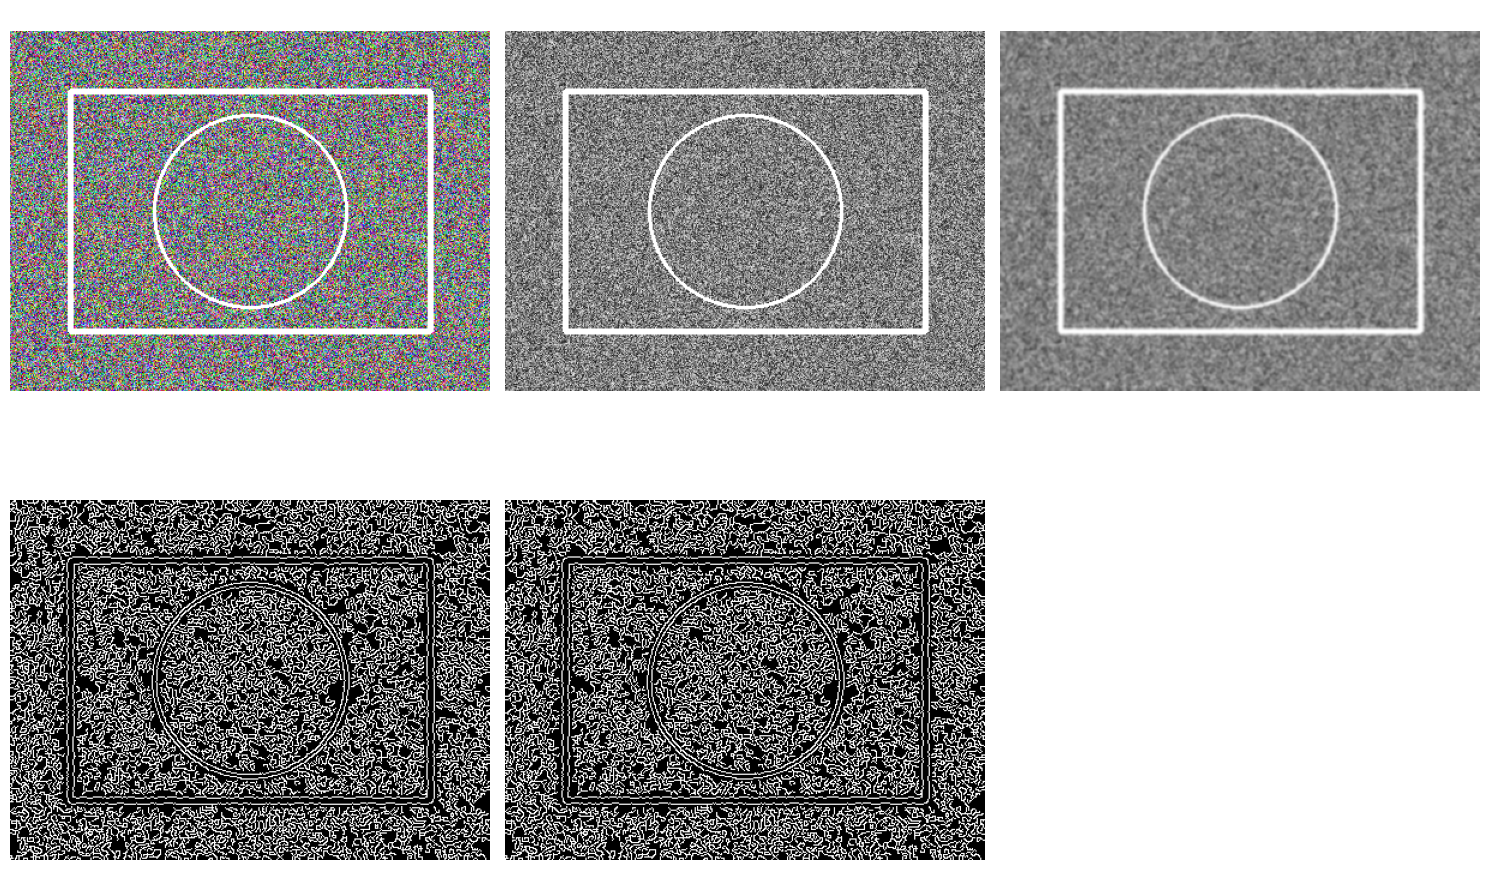

✅ Pipeline completed successfully!


In [ ]:
# TODO: 建立一個影像處理管線
def image_pipeline(img):
    """
    影像處理管線:
    1. 轉灰階
    2. 高斯模糊
    3. 邊緣檢測
    4. 二值化
    """
    # Step 1: 轉灰階
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Step 2: 高斯模糊
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Step 3: 邊緣檢測
    edges = cv2.Canny(blurred, 50, 150)

    # Step 4: 二值化
    _, binary = cv2.threshold(edges, 127, 255, cv2.THRESH_BINARY)

    return gray, blurred, edges, binary

# 測試管線
test_img = np.random.randint(0, 256, (300, 400, 3), dtype=np.uint8)
# 加入一些結構
cv2.rectangle(test_img, (50, 50), (350, 250), (255, 255, 255), 3)
cv2.circle(test_img, (200, 150), 80, (255, 255, 255), 2)

gray, blurred, edges, binary = image_pipeline(test_img)

# 顯示所有步驟
results = [
    cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB),
    cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB),
    cv2.cvtColor(blurred, cv2.COLOR_GRAY2RGB),
    cv2.cvtColor(edges, cv2.COLOR_GRAY2RGB),
    cv2.cvtColor(binary, cv2.COLOR_GRAY2RGB)
]

titles = ['Original', 'Grayscale', 'Blurred', 'Edges', 'Binary']
display_multiple_images(results, titles, rows=2, cols=3, figsize=(15, 10))

print('✅ Pipeline completed successfully!')

### 練習 2: 效能基準測試

In [ ]:
# TODO: 比較不同操作的效能
import time

def benchmark_function(func, iterations=10):
    times = []
    for _ in range(iterations):
        t0 = time.perf_counter()
        func()
        times.append(time.perf_counter() - t0)
    return {
        'average': sum(times) / len(times),
        'min':     min(times),
        'max':     max(times),
    }

# 創建測試影像
sizes = [(480, 640), (720, 1280), (1080, 1920)]

print('\n效能基準測試')
print('='*80)

for height, width in sizes:
    test_img = np.random.randint(0, 256, (height, width, 3), dtype=np.uint8)

    print(f'\n📐 Image size: {width}x{height} ({width*height/1e6:.1f}MP)')
    print('-'*80)

    # 測試各種操作
    operations = [
        ('Color conversion', lambda: cv2.cvtColor(test_img, cv2.COLOR_BGR2GRAY)),
        ('Gaussian blur', lambda: cv2.GaussianBlur(test_img, (15, 15), 0)),
        ('Resize (50%)', lambda: cv2.resize(test_img, (width//2, height//2))),
        ('Flip', lambda: cv2.flip(test_img, 1)),
    ]

    for name, func in operations:
        stats = benchmark_function(func, iterations=10)
        print(f"{name:20} | Avg: {stats['average']*1000:6.2f}ms | "
              f"Min: {stats['min']*1000:6.2f}ms | Max: {stats['max']*1000:6.2f}ms")


效能基準測試

📐 Image size: 640x480 (0.3MP)
--------------------------------------------------------------------------------
Color conversion     | Avg:   0.08ms | Min:   0.03ms | Max:   0.20ms
Gaussian blur        | Avg:   0.46ms | Min:   0.35ms | Max:   0.59ms
Resize (50%)         | Avg:   0.08ms | Min:   0.06ms | Max:   0.16ms
Flip                 | Avg:   0.05ms | Min:   0.05ms | Max:   0.06ms

📐 Image size: 1280x720 (0.9MP)
--------------------------------------------------------------------------------
Color conversion     | Avg:   0.12ms | Min:   0.07ms | Max:   0.25ms
Gaussian blur        | Avg:   1.18ms | Min:   1.11ms | Max:   1.30ms
Resize (50%)         | Avg:   0.10ms | Min:   0.06ms | Max:   0.18ms
Flip                 | Avg:   0.74ms | Min:   0.61ms | Max:   0.97ms

📐 Image size: 1920x1080 (2.1MP)
--------------------------------------------------------------------------------
Color conversion     | Avg:   0.68ms | Min:   0.60ms | Max:   0.87ms
Gaussian blur        | Avg:   2.

## 9. 總結

### 核心知識點

1. **OpenCV 架構**
   - 16個核心模組 (core, imgproc, video, ml, dnn, etc.)
   - 模組間依賴關係
   - Python 綁定使用 NumPy ndarray

2. **資料結構**
   - Mat (NumPy ndarray)
   - Point, Rect, Scalar
   - 影像屬性: shape, dtype, size

3. **常用函數**
   - I/O: imread, imwrite, imshow
   - 色彩: cvtColor
   - 幾何: resize, flip, rotate, warp
   - 濾波: GaussianBlur, medianBlur, bilateralFilter

4. **最佳實踐**
   - 使用 OpenCV 原生函數 (比 NumPy 快)
   - 避免像素級迴圈
   - 使用向量化操作
   - 正確處理錯誤

5. **除錯技巧**
   - 檢查 None 值
   - 驗證影像尺寸
   - 使用 try-except 捕捉錯誤
   - 監控效能

### 下一步學習路徑

```
階段一：基礎概念 ✅
  ├─ Python/NumPy 基礎 ✅
  ├─ OpenCV 安裝 ✅
  ├─ 電腦視覺概念 ✅
  └─ OpenCV 基礎 ✅ ← 你在這裡

階段二：核心操作 🔄
  ├─ 影像 I/O 與顯示
  ├─ 幾何變換
  ├─ 色彩空間轉換
  └─ 算術運算與混合

階段三：前處理技術 ⏳
  ├─ 濾波與平滑
  ├─ 形態學操作
  ├─ 邊緣檢測
  └─ 直方圖處理
```

### 實用資源

- 📖 [OpenCV 官方文檔](https://docs.opencv.org/5.0)

### 參考資源
1. Rafael C. Gonzalez , Richard E. Woods (2017). Digital image processing 4rd. Publisher: Pearson FT Press
2. Davies, E. R. (2017). Computer vision: principles, algorithms, applications 5ed, learning. Publisher: Academic Press.
3. Tyler, Christopher W.(2019). Computer Vision From Surfaces to 3D Objects. Publisher: CRC
4. Szeliski, R. (2022). Computer Vision Algorithms and Applications 2rd. Publisher: Springer
5. Zhang, Y. J. (2022). 2-D Computer Vision Principles, Algorithms and Applications. Publisher: World Scientific Pub
6. Zhang, Y. J. (2023). 3-D Computer Vision: Principles, Algorithms and Applications. Publisher: Springer.
7. Torralba, A., Isola, P., & Freeman, W. T. (2024). Foundations of computer vision. Publisher: MIT Press.
8. Nixon, M., & Aguado, A. S. (2025). Feature extraction and image processing for computer vision 5ed. Publisher: Academic press.

### 檢查清單

- [ ] 理解 OpenCV 16個核心模組
- [ ] 掌握 Mat/ndarray 資料結構
- [ ] 熟悉常用函數 API
- [ ] 能建立完整影像處理流程
- [ ] 知道效能最佳化技巧
- [ ] 會使用錯誤處理機制